# Figure 4 — submission notebook

Authoritative panels B–F are independently replotted from local HDF5 data before compilation.

## Plot-only execution contract

This notebook renders existing intermediate numerical results only. It does not recompute upstream analysis.


In [1]:
PLOT_ONLY_FIGURE = "Figure_4"
ANALYSIS_RECOMPUTED = False
ALLOWED_INPUT_SUFFIXES = {".h5ad", ".h5", ".csv", ".gz", ".parquet", ".json"}
print(PLOT_ONLY_FIGURE, "plot-only mode; analysis_recomputed=", ANALYSIS_RECOMPUTED)

Figure_4 plot-only mode; analysis_recomputed= False


In [2]:
# Conventional Jupyter inline plotting: live Matplotlib figures are rendered by plt.show().
get_ipython().run_line_magic('matplotlib', 'inline')

# Figure 4 — in-house TNBC cell identity, H-cluster markers, CNV, and TNBCtype

Strictly plot-only notebook. Every panel reads the final local Figure 4 HDF5 package; no upstream analysis data are accessed at plotting time.


## Setup, validation, and shared style

In [3]:
from pathlib import Path
import platform, warnings

import h5py
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap, TwoSlopeNorm
from matplotlib.patches import Patch, Rectangle
import numpy as np
import pandas as pd

# ─── Figure parameters (user-editable) ───────────────────────────────
FONT_FAMILY = ["Arial", "Helvetica", "DejaVu Sans"]
PANEL_LABEL_SIZE_PT = 10
AXIS_TITLE_SIZE_PT = 9
TICK_LABEL_SIZE_PT = 7
LEGEND_SIZE_PT = 7
COLORBAR_LABEL_SIZE_PT = 8
UMAP_POINT_SIZE = 0.30
UMAP_ALPHA = 0.80
RASTERIZED = True
H_HEATMAP_CMAP = "bwr"
H_HEATMAP_VMIN = -3
H_HEATMAP_VMAX = 3
PANEL_A_FIGSIZE = (7.1, 5.8)
PANEL_B_FIGSIZE = (16.0, 6.8)
PANEL_C_FIGSIZE = (14.0, 10.0)
METADATA_TRACK_HEIGHT_RATIO = 0.030
CLUSTER_BAR_HEIGHT_RATIO = 0.055
MARKER_SOURCE_WIDTH_RATIO = 0.008
COLORBAR_WIDTH_RATIO = 0.022
LEGEND_WIDTH_RATIO = 0.18
ANNOTATION_TRACK_LABEL_SIZE_PT = 5.5
ANNOTATION_LEGEND_SIZE_PT = 5.5
ANNOTATION_HSPACE = 0.002
ANNOTATION_WSPACE = 0.018
MARKER_TITLE_SIZE_PT = 8
MARKER_COLORBAR_TICK_SIZE_PT = 6
MARKER_COLORBAR_SHRINK = 0.68
MARKER_COLORBAR_PAD = 0.015
UMAP_LIMIT_PADDING = 0.02
PANEL_D_FIGSIZE = (11.0, 6.2)
EXPECTED_CELLS = 69_391
# ─────────────────────────────────────────────────────────────────────

NOTEBOOK_DIR = Path.cwd().resolve()
PLOT_DATA = NOTEBOOK_DIR / "data/fig4_plot_data.h5"
PATIENT_MAPPING_DATA = NOTEBOOK_DIR / "data/patient_id_mapping.csv"
OUTPUT_DIR = NOTEBOOK_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DPI = 300


if not PLOT_DATA.is_file():
    raise FileNotFoundError(f"Missing Figure 4 plot-only bundle: {PLOT_DATA}")
if not PATIENT_MAPPING_DATA.is_file():
    raise FileNotFoundError(f"Missing local Figure 4 patient mapping: {PATIENT_MAPPING_DATA}")
patient_mapping = pd.read_csv(PATIENT_MAPPING_DATA, dtype=str)
if list(patient_mapping.columns) != ["display_id", "patient_id"] or patient_mapping["display_id"].tolist() != [f"P{i}" for i in range(1, 8)]:
    raise RuntimeError("Invalid local Figure 4 patient display mapping")
PATIENT_DISPLAY = patient_mapping.set_index("patient_id")["display_id"].to_dict()

def read_strings(dataset):
    return np.asarray(dataset.asstr()[:], dtype=str)

required_groups = {"shared", "panel_a", "panel_b", "panel_c", "panel_d", "panel_e", "panel_f", "panel_g"}
with h5py.File(PLOT_DATA, "r") as bundle:
    missing_groups = sorted(required_groups.difference(bundle.keys()))
    if missing_groups:
        raise RuntimeError(f"Plot-data bundle lacks groups: {missing_groups}")
    cell_ids = pd.Index(read_strings(bundle["shared/cell_id"]), name="cell_id")
    umap = np.asarray(bundle["shared/umap"][:], dtype=np.float32)
    schema_version = str(bundle.attrs.get("schema_version", "unknown"))
if len(cell_ids) != EXPECTED_CELLS or umap.shape != (EXPECTED_CELLS, 2) or cell_ids.has_duplicates:
    raise RuntimeError("Invalid shared cell IDs or UMAP coordinates in plot-data bundle")

mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": FONT_FAMILY,
    "font.size": TICK_LABEL_SIZE_PT, "axes.titlesize": PANEL_LABEL_SIZE_PT,
    "axes.labelsize": AXIS_TITLE_SIZE_PT, "xtick.labelsize": TICK_LABEL_SIZE_PT,
    "ytick.labelsize": TICK_LABEL_SIZE_PT, "legend.fontsize": LEGEND_SIZE_PT,
    "axes.grid": False, "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "ps.fonttype": 42, "figure.facecolor": "white",
})
warnings.filterwarnings("ignore", category=FutureWarning)
print(f"Validated plot-only bundle schema {schema_version} | {len(cell_ids):,} cells | Python {platform.python_version()} | matplotlib {mpl.__version__}")
print("Rendering path: HDF5 + NumPy/Pandas + Matplotlib only; no analysis or preprocessing is run.")

Validated plot-only bundle schema 2.1 | 69,391 cells | Python 3.9.21 | matplotlib 3.9.2
Rendering path: HDF5 + NumPy/Pandas + Matplotlib only; no analysis or preprocessing is run.


## A — DE-based final cell type

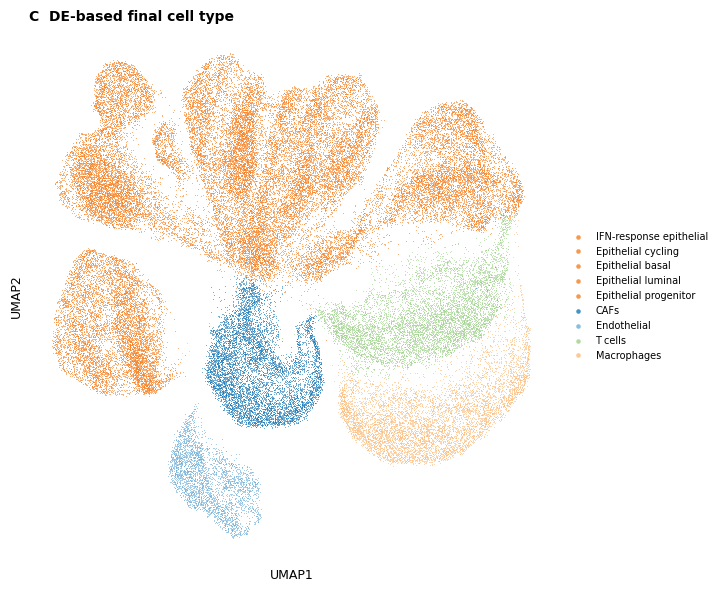

Panel C UMAP: 69,391 cells loaded from the plot-only bundle.


In [4]:
# Reference Figure 4C palette (lineage-level colors).
CELLTYPE_COLORS = {
    "IFN-response epithelial": "#F57F20", "Epithelial cycling": "#F57F20",
    "Epithelial": "#F57F20", "Epithelial basal": "#F57F20",
    "Epithelial luminal": "#F57F20", "Epithelial stress/EMT": "#F57F20",
    "Epithelial progenitor": "#F57F20", "CAFs": "#1878B6",
    "Endothelial": "#6BAED6", "T cells": "#9DD189",
    "Macrophages": "#FCBB78",
}

with h5py.File(PLOT_DATA, "r") as bundle:
    labels = read_strings(bundle["panel_a/celltype"])
if labels.shape != (EXPECTED_CELLS,):
    raise RuntimeError("Panel A plot labels have unexpected dimensions")
unexpected = sorted(set(labels).difference(CELLTYPE_COLORS))
if unexpected:
    raise RuntimeError(f"Unexpected DE-based cell types: {unexpected}")

fig, ax = plt.subplots(figsize=PANEL_A_FIGSIZE, constrained_layout=True)
for label, color in CELLTYPE_COLORS.items():
    mask = labels == label
    if mask.any():
        ax.scatter(umap[mask, 0], umap[mask, 1], s=UMAP_POINT_SIZE, alpha=UMAP_ALPHA,
                   color=color, linewidths=0, rasterized=RASTERIZED, label=label)
ax.set_title("C  DE-based final cell type", loc="left", fontweight="bold")
ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel("UMAP1"); ax.set_ylabel("UMAP2")
ax.spines[:].set_visible(False)
ax.legend(frameon=False, bbox_to_anchor=(1.01, 0.5), loc="center left", markerscale=6)
plt.show(); plt.close(fig)
del labels
print(f"Panel C UMAP: {len(cell_ids):,} cells loaded from the plot-only bundle.")

## D — Canonical H-cluster marker expression

Eight marker-expression UMAPs are arranged as four compact panels above four compact panels, with visible UMAP axes and external expression colour bars.


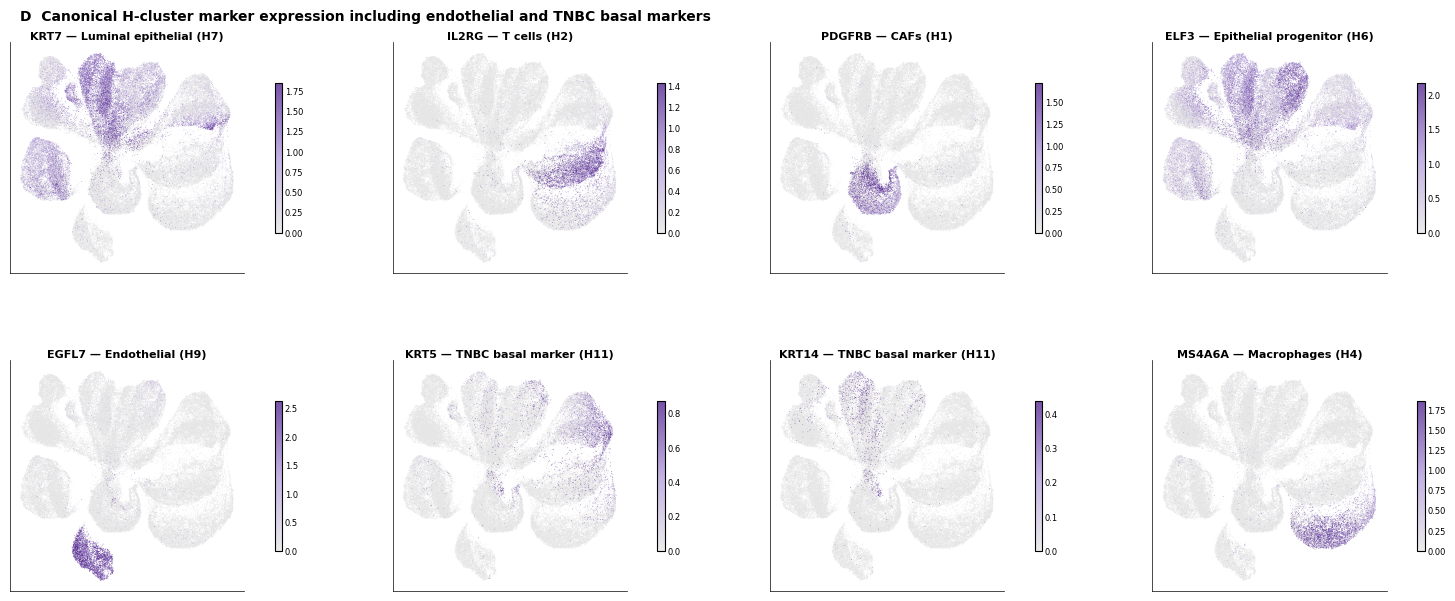

Panel D: 8 canonical marker-expression UMAPs loaded from the plot-only bundle.


In [5]:
# Panel D: eight canonical H-cluster marker-expression UMAPs, arranged 4 over 4
MARKER_GENES = ["KRT7", "IL2RG", "PDGFRB", "ELF3", "EGFL7", "KRT5", "KRT14", "MS4A6A"]
MARKER_H_CLUSTERS = ["H7", "H2", "H1", "H6", "H9", "H11", "H11", "H4"]
MARKER_LABELS = ["Luminal epithelial", "T cells", "CAFs", "Epithelial progenitor", "Endothelial", "TNBC basal marker", "TNBC basal marker", "Macrophages"]
MARKER_CMAP = LinearSegmentedColormap.from_list("marker_grey_to_purple", ["#E6E6E6", "#B39DDB", "#54278F"])
MARKER_AXIS_LABEL_PT = 5.0
MARKER_AXIS_TICK_PT = 4.0
with h5py.File(PLOT_DATA, "r") as bundle:
    marker_expression = np.asarray(bundle["panel_f/marker_expression"][:], dtype=float)
    marker_genes = read_strings(bundle["panel_f/marker_genes"]).tolist()
    marker_h_clusters = read_strings(bundle["panel_f/marker_h_clusters"]).tolist()
    marker_labels = read_strings(bundle["panel_f/marker_labels"]).tolist()
if marker_expression.shape != (EXPECTED_CELLS, len(MARKER_GENES)) or not np.isfinite(marker_expression).all():
    raise RuntimeError("Panel D marker-expression array is invalid")
if marker_genes != MARKER_GENES or marker_h_clusters != MARKER_H_CLUSTERS or marker_labels != MARKER_LABELS:
    raise RuntimeError("Panel D marker identity/order does not match the plotting contract")
fig = plt.figure(figsize=(14.5, 5.9), constrained_layout=True)
grid = fig.add_gridspec(2, 8, hspace=0.26, wspace=0.46)
panel_specs = [grid[0, 0:2], grid[0, 2:4], grid[0, 4:6], grid[0, 6:8], grid[1, 0:2], grid[1, 2:4], grid[1, 4:6], grid[1, 6:8]]
for panel_spec, gene, h_cluster, label, values in zip(panel_specs, marker_genes, marker_h_clusters, marker_labels, marker_expression.T):
    ax = fig.add_subplot(panel_spec)
    vmin, vmax = np.percentile(values, [2, 98])
    if not vmax > vmin:
        vmax = vmin + 1e-6
    points = ax.scatter(umap[:, 0], umap[:, 1], c=values, cmap=MARKER_CMAP, vmin=vmin, vmax=vmax, s=UMAP_POINT_SIZE, alpha=UMAP_ALPHA, linewidths=0, rasterized=RASTERIZED)
    ax.set_title(f"{gene} — {label} ({h_cluster})", fontsize=MARKER_TITLE_SIZE_PT, fontweight="bold", pad=2)
    ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_xticks([]); ax.set_yticks([]); ax.tick_params(bottom=False, left=False)
    ax.grid(False); ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("black"); ax.spines["bottom"].set_color("black")
    ax.spines["left"].set_linewidth(0.5); ax.spines["bottom"].set_linewidth(0.5)
    colorbar = fig.colorbar(points, ax=ax, fraction=0.032, pad=0.13)
    colorbar.ax.tick_params(labelsize=MARKER_COLORBAR_TICK_SIZE_PT, length=1, width=0.35, pad=1)
fig.suptitle("D  Canonical H-cluster marker expression including endothelial and TNBC basal markers", x=0.01, ha="left", fontsize=PANEL_LABEL_SIZE_PT, fontweight="bold")
display(fig); plt.close(fig)
print(f"Panel D: {len(marker_genes)} canonical marker-expression UMAPs loaded from the plot-only bundle.")

### Marker-expression display note

Each map uses its own 2nd–98th percentile scale because the canonical marker genes have different expression ranges.


In [6]:
print("Panel D uses canonical marker expression (KRT7, IL2RG, PDGFRB, ELF3); prior activity-score maps are replaced.")

Panel D uses canonical marker expression (KRT7, IL2RG, PDGFRB, ELF3); prior activity-score maps are replaced.


## C — All-cell H-cluster marker expression

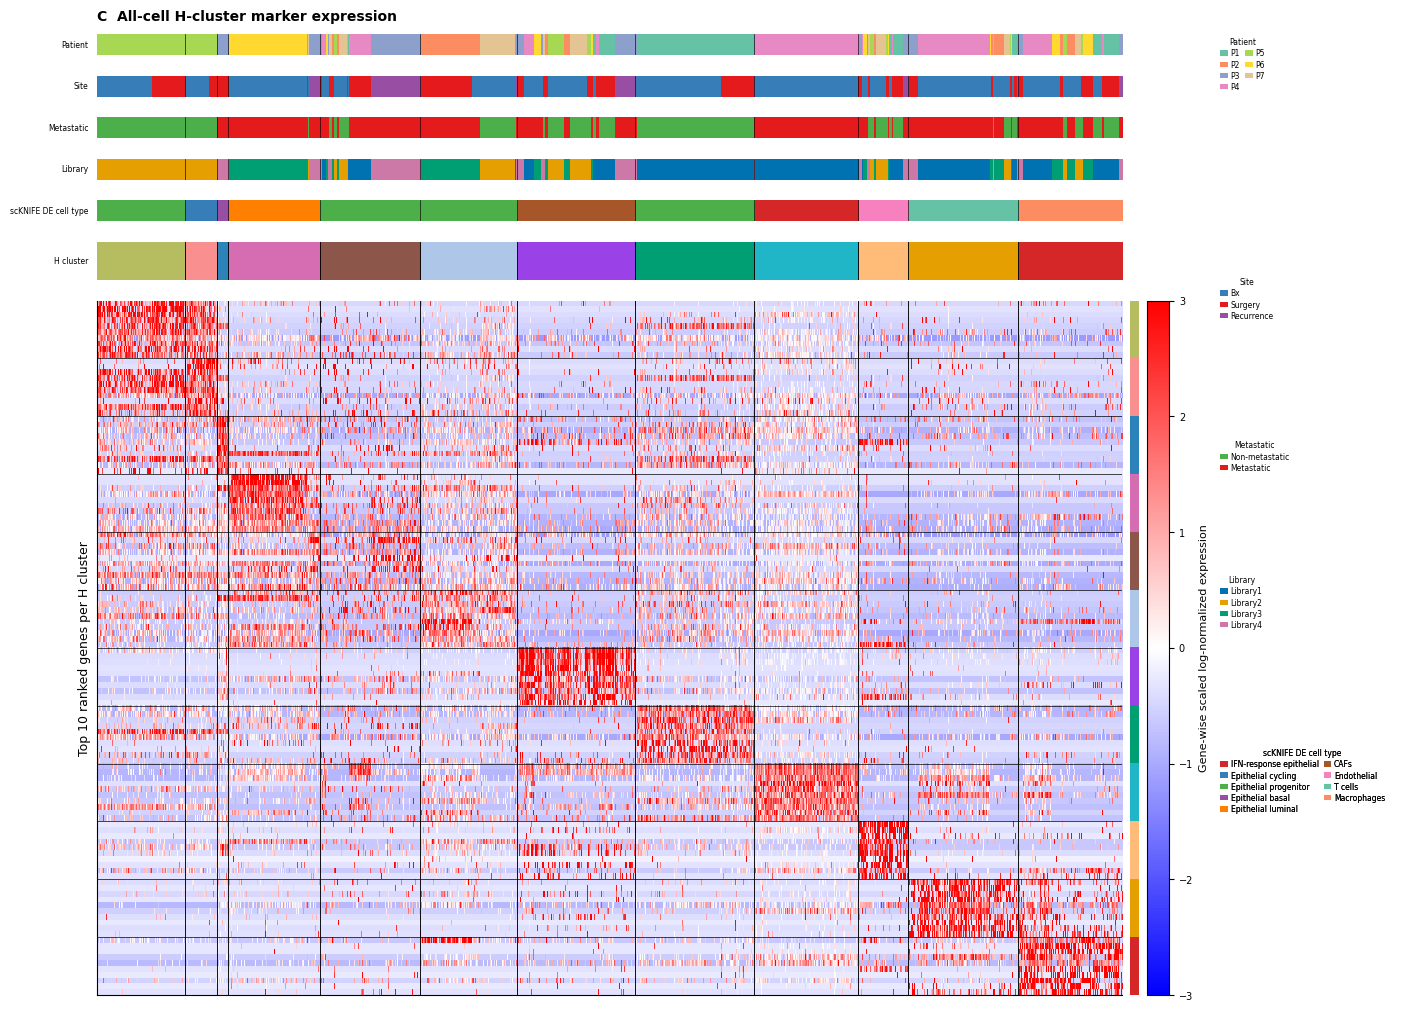

Panel C: 120 marker slots × 69,391 cells × 5 metadata tracks loaded from the plot-only bundle.


In [7]:
H_ORDER = ["H8", "H10", "H11", "H7", "H5", "H6", "H1", "H0", "H3", "H9", "H2", "H4"]
H_GROUPS = [f"H{i}" for i in range(12)]
H_COLORS = dict(zip(H_GROUPS, ["#009E73", "#9A42E8", "#E69F00", "#21B6C7", "#D62728", "#8C564B", "#AEC7E8", "#D66DB3", "#B6BD61", "#FFBB78", "#FA8F8F", "#2B83BA"]))
METADATA_TRACKS = [("Patient", "Patient IDs"), ("Site", "Site"), ("Metastatic", "Metastatic"), ("Library", "library"), ("scKNIFE DE cell type", "scknife_final_celltype")]
PATIENT_ORDER_C = ["P1", "P2", "P3", "P4", "P5", "P6", "P7"]
SITE_ORDER_C = ["Bx", "Surgery", "Recurrence"]
METASTATIC_ORDER_C = ["Non-metastatic", "Metastatic"]
LIBRARY_ORDER_C = ["Library1", "Library2", "Library3", "Library4"]
DE_ORDER_C = ["IFN-response epithelial", "Epithelial cycling", "Epithelial progenitor", "Epithelial basal", "Epithelial luminal", "CAFs", "Endothelial", "T cells", "Macrophages"]
METADATA_ORDERS = {"Patient IDs": PATIENT_ORDER_C, "Site": SITE_ORDER_C, "Metastatic": METASTATIC_ORDER_C, "library": LIBRARY_ORDER_C, "scknife_final_celltype": DE_ORDER_C}
PATIENT_COLORS_C = dict(zip(PATIENT_ORDER_C, ["#66C2A5", "#FC8D62", "#8DA0CB", "#E78AC3", "#A6D854", "#FFD92F", "#E5C494"]))
SITE_COLORS_C = {"Bx": "#377EB8", "Surgery": "#E41A1C", "Recurrence": "#984EA3"}
METASTATIC_COLORS_C = {"Non-metastatic": "#4DAF4A", "Metastatic": "#E41A1C"}
LIBRARY_COLORS_C = {"Library1": "#0072B2", "Library2": "#E69F00", "Library3": "#009E73", "Library4": "#CC79A7"}
DE_COLORS_C = {"IFN-response epithelial": "#D62728", "Epithelial cycling": "#377EB8", "Epithelial progenitor": "#4DAF4A", "Epithelial basal": "#984EA3", "Epithelial luminal": "#FF7F00", "CAFs": "#A65628", "Endothelial": "#F781BF", "T cells": "#66C2A5", "Macrophages": "#FC8D62"}

METADATA_COLORS = {"Patient IDs": PATIENT_COLORS_C, "Site": SITE_COLORS_C, "Metastatic": METASTATIC_COLORS_C, "library": LIBRARY_COLORS_C, "scknife_final_celltype": DE_COLORS_C}
METADATA_DISPLAY = {"Patient IDs": PATIENT_DISPLAY}
EXPECTED_H_COUNTS = {"H0":8009, "H1":7981, "H2":7461, "H3":7082, "H4":7001, "H5":6780, "H6":6595, "H7":6193, "H8":5966, "H9":3374, "H10":2177, "H11":772}

with h5py.File(PLOT_DATA, "r") as bundle:
    heatmap = np.asarray(bundle["panel_c/heatmap"][:], dtype=np.float32)
    display_genes = read_strings(bundle["panel_c/display_genes"]).tolist()
    marker_groups = read_strings(bundle["panel_c/marker_groups"])
    ordered_labels = read_strings(bundle["panel_c/h_cluster"])
    boundaries = np.asarray(bundle["panel_c/boundaries"][:], dtype=np.int64)
    ordered_metadata = pd.DataFrame({
        "Patient IDs": read_strings(bundle["panel_c/patient"]),
        "Site": read_strings(bundle["panel_c/site"]),
        "Metastatic": read_strings(bundle["panel_c/metastatic"]),
        "library": read_strings(bundle["panel_c/library"]),
        "scknife_final_celltype": read_strings(bundle["panel_c/scknife_final_celltype"]),
    })
if heatmap.shape != (120, EXPECTED_CELLS) or len(display_genes) != 120 or marker_groups.shape != (120,):
    raise RuntimeError("Panel C heatmap or marker dimensions do not match the plotting contract")
if ordered_labels.shape != (EXPECTED_CELLS,) or len(ordered_metadata) != EXPECTED_CELLS or not np.isfinite(heatmap).all():
    raise RuntimeError("Panel C cell annotations or heatmap values are invalid")
observed_counts = pd.Series(ordered_labels).value_counts().sort_index().astype(int).to_dict()
expected_boundaries = np.flatnonzero(ordered_labels[1:] != ordered_labels[:-1]) + 1
if observed_counts != EXPECTED_H_COUNTS or not np.array_equal(boundaries, expected_boundaries):
    raise RuntimeError("Panel C H-cluster counts or boundaries changed")
de_celltype_by_h_cluster = {}
for group in H_GROUPS:
    observed = ordered_metadata.loc[ordered_labels == group, "scknife_final_celltype"].unique()
    if len(observed) != 1:
        raise RuntimeError(f"Panel C scKNIFE DE cell-type track is not constant within {group}: {observed.tolist()}")
    de_celltype_by_h_cluster[group] = str(observed[0])
for _, column in METADATA_TRACKS:
    unexpected = sorted(set(ordered_metadata[column]).difference(METADATA_ORDERS[column]))
    if unexpected:
        raise RuntimeError(f"Unexpected categories in bundled Panel C {column}: {unexpected}")

n_metadata_tracks = len(METADATA_TRACKS)
h_cluster_track_row = n_metadata_tracks
heatmap_row = h_cluster_track_row + 1
fig = plt.figure(figsize=PANEL_C_FIGSIZE, constrained_layout=True)
grid = fig.add_gridspec(
    n_metadata_tracks + 2, 4,
    width_ratios=[1.0, MARKER_SOURCE_WIDTH_RATIO, COLORBAR_WIDTH_RATIO, LEGEND_WIDTH_RATIO],
    height_ratios=[METADATA_TRACK_HEIGHT_RATIO] * n_metadata_tracks + [CLUSTER_BAR_HEIGHT_RATIO, 1.0],
    hspace=ANNOTATION_HSPACE, wspace=ANNOTATION_WSPACE,
)
for row, (label, column) in enumerate(METADATA_TRACKS):
    track_ax = fig.add_subplot(grid[row, 0])
    categories = METADATA_ORDERS[column]
    category_index = {category: index for index, category in enumerate(categories)}
    encoded = ordered_metadata[column].astype(str).map(category_index).to_numpy()[None, :]
    track_ax.imshow(
        encoded, aspect="auto", interpolation="nearest",
        cmap=ListedColormap([METADATA_COLORS[column][category] for category in categories]),
        vmin=0, vmax=max(1, len(categories) - 1),
    )
    for position in boundaries:
        track_ax.axvline(position - 0.5, color="black", linewidth=0.45)
    track_ax.set_xticks([]); track_ax.set_yticks([])
    track_ax.set_ylabel(label, rotation=0, ha="right", va="center", fontsize=ANNOTATION_TRACK_LABEL_SIZE_PT)
    track_ax.yaxis.set_label_coords(-0.008, 0.5)
    if row == 0:
        track_ax.set_title("C  All-cell H-cluster marker expression", loc="left", pad=10, fontsize=PANEL_LABEL_SIZE_PT, fontweight="bold")
    for spine in track_ax.spines.values(): spine.set_visible(False)

# The H-cluster strip sits directly beneath the scKNIFE DE cell-type strip and above the heatmap.
h_cluster_ax = fig.add_subplot(grid[h_cluster_track_row, 0])
h_cluster_codes = pd.Series(ordered_labels).map({group: i for i, group in enumerate(H_GROUPS)}).to_numpy()[None, :]
h_cluster_ax.imshow(h_cluster_codes, aspect="auto", interpolation="nearest", cmap=ListedColormap([H_COLORS[group] for group in H_GROUPS]), vmin=0, vmax=11)
for position in boundaries: h_cluster_ax.axvline(position - 0.5, color="black", linewidth=0.65)
h_cluster_ax.set_xticks([]); h_cluster_ax.set_yticks([])
h_cluster_ax.set_ylabel("H cluster", rotation=0, ha="right", va="center", fontsize=ANNOTATION_TRACK_LABEL_SIZE_PT)
h_cluster_ax.yaxis.set_label_coords(-0.008, 0.5)
for spine in h_cluster_ax.spines.values(): spine.set_visible(False)

ax = fig.add_subplot(grid[heatmap_row, 0])
image = ax.imshow(heatmap, aspect="auto", interpolation="nearest", cmap=H_HEATMAP_CMAP, vmin=H_HEATMAP_VMIN, vmax=H_HEATMAP_VMAX, rasterized=RASTERIZED)
for position in boundaries: ax.axvline(position - 0.5, color="black", linewidth=0.65)
for position in range(10, len(display_genes), 10): ax.axhline(position - 0.5, color="black", linewidth=0.50)
ax.set_xticks([]); ax.set_yticks([]); ax.set_ylabel("Top 10 ranked genes per H cluster")

source_ax = fig.add_subplot(grid[heatmap_row, 1])
source_codes = pd.Series(marker_groups).map({group: i for i, group in enumerate(H_GROUPS)}).to_numpy()[:, None]
source_ax.imshow(source_codes, aspect="auto", interpolation="nearest", cmap=ListedColormap([H_COLORS[g] for g in H_GROUPS]), vmin=0, vmax=11)
source_ax.set_xticks([]); source_ax.set_yticks([]); source_ax.spines[:].set_visible(False)

cbar_ax = fig.add_subplot(grid[heatmap_row, 2])
cbar = fig.colorbar(image, cax=cbar_ax)
cbar.set_label("Gene-wise scaled log-normalized expression", fontsize=COLORBAR_LABEL_SIZE_PT)

legend_ax = fig.add_subplot(grid[:, 3]); legend_ax.axis("off")
legend_y = 1.0
legend_steps = {"Patient IDs": 0.25, "Site": 0.17, "Metastatic": 0.14, "library": 0.18, "scknife_final_celltype": 0.30}
for label, column in METADATA_TRACKS:
    handles = [Patch(facecolor=METADATA_COLORS[column][category], edgecolor="none", label=METADATA_DISPLAY.get(column, {}).get(category, category)) for category in METADATA_ORDERS[column]]
    legend = legend_ax.legend(
        handles=handles, title=label, loc="upper left", bbox_to_anchor=(0, legend_y),
        frameon=False, fontsize=ANNOTATION_LEGEND_SIZE_PT, title_fontsize=ANNOTATION_LEGEND_SIZE_PT,
        ncol=2 if column in {"Patient IDs", "scknife_final_celltype"} else 1, borderaxespad=0,
        handlelength=1.0, handletextpad=0.35, columnspacing=0.65, labelspacing=0.30,
    )
    legend_ax.add_artist(legend)
    legend_y -= legend_steps[column]
plt.show(); plt.close(fig)
del heatmap
print(f"Panel C: {len(display_genes)} marker slots × {len(ordered_labels):,} cells × {n_metadata_tracks} metadata tracks loaded from the plot-only bundle.")

## E — Patient-level TNBCtype web-tool recommendation

One official TNBCtype recommendation is shown per patient from epithelial pseudobulk; this is not a single-cell subtype assignment.


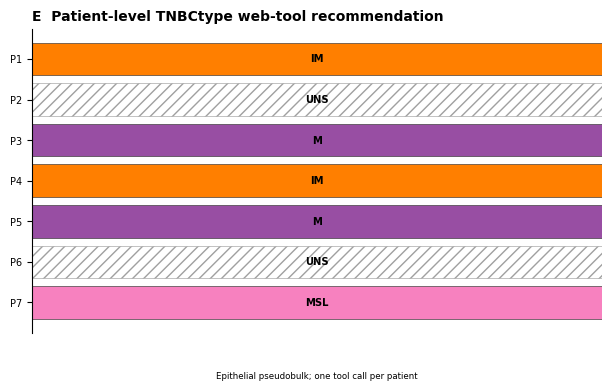

Panel E: official patient-level TNBCtype web-tool recommendations loaded from the plot-only bundle.


In [8]:
# Panel E: patient-level TNBCtype web-tool recommendation
TNBC_PATIENT_ORDER = ["P1", "P2", "P3", "P4", "P5", "P6", "P7"]
TNBC_SUBTYPE_COLORS = {"M": "#984EA3", "IM": "#FF7F00", "MSL": "#F781BF", "UNS": "#A0A0A0"}
with h5py.File(PLOT_DATA, "r") as bundle:
    subtype_patients = read_strings(bundle["panel_g/patient"]).tolist()
    subtype_calls = read_strings(bundle["panel_g/subtype"]).tolist()
if set(subtype_patients) != set(TNBC_PATIENT_ORDER) or set(subtype_calls) != set(TNBC_SUBTYPE_COLORS):
    raise RuntimeError("Panel E TNBCtype patient/call data are invalid")
subtype_table = pd.DataFrame({"Patient": subtype_patients, "Subtype": subtype_calls}).set_index("Patient").loc[TNBC_PATIENT_ORDER]
fig, ax = plt.subplots(figsize=(6.0, 3.8), constrained_layout=True)
for index, (patient, row) in enumerate(subtype_table.iterrows()):
    subtype = row["Subtype"]
    bar = ax.barh(index, 1.0, color=TNBC_SUBTYPE_COLORS[subtype], edgecolor="#333333", linewidth=0.45)[0]
    if subtype == "UNS":
        bar.set_facecolor("white"); bar.set_hatch("///"); bar.set_edgecolor(TNBC_SUBTYPE_COLORS["UNS"])
    ax.text(0.5, index, subtype, va="center", ha="center", fontsize=7.2, fontweight="bold")
ax.set_yticks(np.arange(len(subtype_table)), [PATIENT_DISPLAY[patient] for patient in subtype_table.index])
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xticks([])
ax.set_title("E  Patient-level TNBCtype web-tool recommendation", loc="left", fontweight="bold")
ax.text(0.5, -0.13, "Epithelial pseudobulk; one tool call per patient", transform=ax.transAxes, ha="center", va="top", fontsize=6.2)
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False); ax.spines["bottom"].set_visible(False); ax.grid(False)
display(fig); plt.close(fig)
print("Panel E: official patient-level TNBCtype web-tool recommendations loaded from the plot-only bundle.")

## B — CNV score by final CNV-cluster-derived status

Complete violins show the final tutorial-derived CNV-cluster scores. Scores are repeated within each CNV cluster and are not independent per-cell measurements.


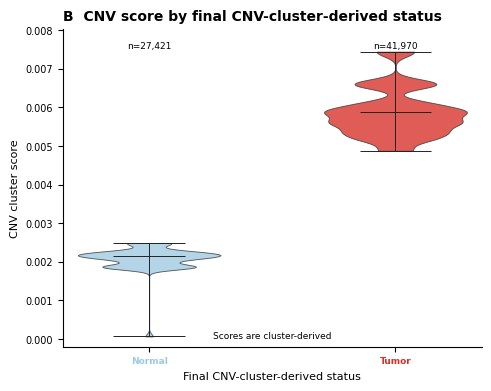

In [9]:
# Panel B: complete CNV violins using final CNV-cluster-derived status
CNV_STATUS_ORDER = ["normal", "tumor"]
CNV_STATUS_LABELS = {"normal": "Normal", "tumor": "Tumor"}
CNV_STATUS_COLORS = {"normal": "#9ECAE1", "tumor": "#D73027"}
with h5py.File(PLOT_DATA, "r") as bundle:
    cnv_status = read_strings(bundle["panel_e/cnv_status"])
    cnv_score = np.asarray(bundle["panel_e/cnv_score"][:], dtype=float)
if len(cnv_status) != EXPECTED_CELLS or cnv_score.shape != (EXPECTED_CELLS,) or not np.isfinite(cnv_score).all():
    raise RuntimeError("Panel B CNV status/score data are invalid")
if set(cnv_status) != set(CNV_STATUS_ORDER):
    raise RuntimeError(f"Unexpected CNV statuses: {sorted(set(cnv_status))}")
cnv_values = [cnv_score[cnv_status == status] for status in CNV_STATUS_ORDER]
def draw_cnv_status_violin(ax, values, positions, labels, colors, tick_size, text_size, max_score, show_note=True):
    violin = ax.violinplot(values, positions=positions, widths=0.58, showmeans=False, showmedians=True, showextrema=True, bw_method=0.20)
    for body, color in zip(violin["bodies"], colors):
        body.set_facecolor(color); body.set_edgecolor("#333333"); body.set_alpha(0.78); body.set_linewidth(0.65)
    for key in ("cbars", "cmins", "cmaxes", "cmedians"):
        violin[key].set_color("#222222"); violin[key].set_linewidth(0.70)
    margin = max(0.35, 0.22 * (positions[-1] - positions[0]))
    ax.set_xlim(positions[0] - margin, positions[-1] + margin)
    ax.set_ylim(-0.0002, float(max_score) * 1.08)
    ax.set_xticks(positions, labels, fontsize=tick_size)
    for tick, color in zip(ax.get_xticklabels(), colors):
        tick.set_color(color); tick.set_fontweight("bold")
    for position, group in zip(positions, values):
        ax.text(position, float(max_score) * 1.035, f"n={len(group):,}", ha="center", va="top", fontsize=tick_size)
    ax.set_xlabel("Final CNV-cluster-derived status", fontsize=text_size)
    ax.set_ylabel("CNV cluster score", fontsize=text_size)
    if show_note:
        ax.text(0.5, 0.02, "Scores are cluster-derived", transform=ax.transAxes, ha="center", va="bottom", fontsize=tick_size)
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False); ax.grid(False)
    return violin

fig, ax = plt.subplots(figsize=(4.8, 3.8), constrained_layout=True)
draw_cnv_status_violin(
    ax, cnv_values, [0, 1], [CNV_STATUS_LABELS[s] for s in CNV_STATUS_ORDER],
    [CNV_STATUS_COLORS[s] for s in CNV_STATUS_ORDER], 6.5, 8, cnv_score.max(), show_note=True,
)
ax.set_title("B  CNV score by final CNV-cluster-derived status", loc="left", fontweight="bold")
display(fig); plt.close(fig)

## Final A4 Figure 4 compilation and export

This independent A4 portrait composition renders B/C/D/E/F directly from the local Figure 4 HDF5 package. It does not read prior figure objects or standalone panel images.


In [10]:
def make_figure4_main_panel(panel_label=None):
    # Exporting the final outcomes: mixed raster/vector Figure 4.
    # Run this section after the validated main compilation cell above.

    from pathlib import Path
    import json, platform
    from IPython.display import display, Image
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    from matplotlib.image import imread
    from matplotlib.lines import Line2D
    from matplotlib.patches import Patch
    import numpy as np

    mpl.rcParams.update({"svg.fonttype": "none", "pdf.fonttype": 42, "pdf.use14corefonts": False})

    import csv, h5py, tempfile

    FIG4_DPI = 300
    FIG4_LABEL_PT, FIG4_TEXT_PT, FIG4_TICK_PT = 8.5, 6.2, 4.8
    FIG4_UMAP_TITLE_PT, FIG4_POINT_SIZE, FIG4_ALPHA = 4.0, 0.22, 0.80
    FIG4_SOURCE_RECTS = {"C": (12, 229, 70, 55), "F": (86, 175, 112, 109), "E": (12, 175, 70, 48), "D": (12, 95, 144, 72), "B": (160, 95, 38, 72)}
    if panel_label is None:
        FIG4_W_MM, FIG4_H_MM = 210, 297
        FIG4_LAYOUT_RECTS = FIG4_SOURCE_RECTS
    elif panel_label in FIG4_SOURCE_RECTS:
        _, _, FIG4_W_MM, FIG4_H_MM = FIG4_SOURCE_RECTS[panel_label]
        FIG4_LAYOUT_RECTS = {panel_label: (0, 0, FIG4_W_MM, FIG4_H_MM)}
    else:
        raise ValueError(f"Unknown Figure 4 panel: {panel_label}")
    FIG4_RECTS = FIG4_SOURCE_RECTS

    mix_root = Path.cwd().resolve()
    data_path = mix_root / "data/fig4_plot_data.h5"
    patient_mapping_path = mix_root / "data/patient_id_mapping.csv"
    with patient_mapping_path.open(newline="") as handle:
        patient_display = {row["patient_id"]: row["display_id"] for row in csv.DictReader(handle)}
    mix_patient_order = ["P1", "P2", "P3", "P4", "P5", "P6", "P7"]
    if [patient_display.get(p) for p in mix_patient_order] != [f"P{i}" for i in range(1, 8)]:
        raise RuntimeError("Invalid local Figure 4 patient display mapping")

    def rs(x):
        return np.asarray(x.asstr()[:], dtype=str)

    with h5py.File(data_path, "r") as f:
        schema = str(f.attrs.get("schema_version", "unknown"))
        u = np.asarray(f["shared/umap"][:], np.float32)
        ct = rs(f["panel_a/celltype"])
        hm = np.asarray(f["panel_c/heatmap"][:], np.float32)
        hg = rs(f["panel_c/h_cluster"])
        bd = np.asarray(f["panel_c/boundaries"][:], np.int64)
        mg = rs(f["panel_c/marker_groups"])
        tracks = {"Patient": rs(f["panel_c/patient"]), "Site": rs(f["panel_c/site"]), "Metastatic": rs(f["panel_c/metastatic"]), "Library": rs(f["panel_c/library"]), "scKNIFE DE cell type": rs(f["panel_c/scknife_final_celltype"])}
        cnv_status = rs(f["panel_e/cnv_status"])
        cnv_score = np.asarray(f["panel_e/cnv_score"][:], np.float32)
        marker_expression = np.asarray(f["panel_f/marker_expression"][:], np.float32)
        marker_genes = rs(f["panel_f/marker_genes"]).tolist()
        marker_h_clusters = rs(f["panel_f/marker_h_clusters"]).tolist()
        marker_labels = rs(f["panel_f/marker_labels"]).tolist()
        subtype_patient = rs(f["panel_g/patient"]).tolist()
        subtype_call = rs(f["panel_g/subtype"]).tolist()
        subtype_correlation_matrix = np.asarray(f["panel_g/subtype_correlation_matrix"][:], np.float32)
        subtype_score_subtypes = rs(f["panel_g/subtype_correlation_subtypes"]).tolist()

    # Panel E uses the same H-graph-derived UMAP as the H-cluster panels.
    mix_h_xy = u
    mix_h_score = cnv_score
    if mix_h_xy.shape != (len(mix_h_score), 2) or not np.isfinite(mix_h_xy).all() or not np.isfinite(mix_h_score).all():
        raise RuntimeError("Invalid H-graph CNV-score UMAP inputs")

    if schema != "2.1" or u.shape != (69391, 2) or hm.shape != (120, 69391) or marker_expression.shape != (69391, 8):
        raise RuntimeError("Invalid local Figure 4 plotting package")
    if marker_genes != ["KRT7", "IL2RG", "PDGFRB", "ELF3", "EGFL7", "KRT5", "KRT14", "MS4A6A"] or marker_h_clusters != ["H7", "H2", "H1", "H6", "H9", "H11", "H11", "H4"]:
        raise RuntimeError("Marker identity/order changed")
    if subtype_correlation_matrix.shape != (7, 6) or subtype_score_subtypes != ["IM", "BL1", "MSL", "M", "BL2", "LAR"] or not np.isfinite(subtype_correlation_matrix).all():
        raise RuntimeError("Invalid TNBCtype subtype-correlation inputs")
    if set(cnv_status) != {"normal", "tumor"} or not np.isfinite(cnv_score).all():
        raise RuntimeError("Invalid local CNV inputs")
    if not np.array_equal(bd, np.flatnonzero(hg[1:] != hg[:-1]) + 1):
        raise RuntimeError("Invalid H-cluster boundaries")
    mix_e_order = ["normal", "tumor"]
    mix_e_labels = ["Normal", "Tumor"]
    mix_e_colors = ["#56B4E9", "#D55E00"]
    mix_e_values = [cnv_score[cnv_status == status] for status in mix_e_order]
    if any(len(values) < 2 for values in mix_e_values): raise RuntimeError("Insufficient CNV-score values for error bars")
    mix_e_means = np.array([np.mean(values) for values in mix_e_values], dtype=np.float64)
    mix_e_sem = np.array([np.std(values, ddof=1) / np.sqrt(len(values)) for values in mix_e_values], dtype=np.float64)


    ctc = {"IFN-response epithelial":"#F57F20", "Epithelial cycling":"#F57F20", "Epithelial":"#F57F20", "Epithelial basal":"#F57F20", "Epithelial luminal":"#F57F20", "Epithelial stress/EMT":"#F57F20", "Epithelial progenitor":"#F57F20", "CAFs":"#1878B6", "Endothelial":"#6BAED6", "T cells":"#9DD189", "Macrophages":"#FCBB78"}
    hlist = [f"H{i}" for i in range(12)]
    hcolors = ["#009E73", "#9A42E8", "#E69F00", "#21B6C7", "#D62728", "#8C564B", "#AEC7E8", "#D66DB3", "#B6BD61", "#FFBB78", "#FA8F8F", "#2B83BA"]
    specs = [("Patient", mix_patient_order, ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442"]), ("Site", ["Bx", "Surgery", "Recurrence"], ["#377EB8", "#E41A1C", "#984EA3"]), ("Metastatic", ["Non-metastatic", "Metastatic"], ["#4DAF4A", "#E41A1C"]), ("Library", ["Library1", "Library2", "Library3", "Library4"], ["#1F78B4", "#FFB000", "#33A02C", "#E31A1C"]), ("scKNIFE DE cell type", ["IFN-response epithelial", "Epithelial cycling", "Epithelial progenitor", "Epithelial basal", "Epithelial luminal", "CAFs", "Endothelial", "T cells", "Macrophages"], ["#E41A1C", "#FF7F00", "#33A02C", "#1F78B4", "#6A3D9A", "#A65628", "#17BECF", "#66A61E", "#E7298A"])]

    def mm_box(x, y, w, h):
        return [x / FIG4_W_MM, y / FIG4_H_MM, w / FIG4_W_MM, h / FIG4_H_MM]

    out = mix_root / "outputs"
    MIX_DPI = FIG4_DPI
    mix_out = out
    mix_tempdir = tempfile.TemporaryDirectory(prefix="figure_4_mixed_")
    mix_assets = Path(mix_tempdir.name)

    def mix_inside(rect, left, bottom, width, height):
        x, y, rw, rh = rect
        return mm_box(x + left * rw, y + bottom * rh, width * rw, height * rh)

    def mix_heading(fig, key, title, size=FIG4_LABEL_PT):
        rect = FIG4_LAYOUT_RECTS[key]
        fig.text((rect[0] + .8) / FIG4_W_MM, (rect[1] + rect[3] - 1) / FIG4_H_MM, f"{key}  {title}", ha="left", va="top", fontsize=size, fontweight="bold")
        return rect

    def mix_clean_axis(ax):
        ax.grid(False)
        ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
        ax.spines["left"].set_linewidth(.4); ax.spines["bottom"].set_linewidth(.4)
        ax.tick_params(labelsize=FIG4_TICK_PT, width=.4, length=1.5, pad=1)

    def mix_vector_colorbar(fig, rect, cmap, vmin, vmax, label="", ticks=None):
        cax = fig.add_axes(rect)
        lo, hi = float(vmin), float(vmax)
        if not hi > lo: hi = lo + 1e-6
        edges = np.linspace(lo, hi, 129)
        for start, end in zip(edges[:-1], edges[1:]):
            cax.add_patch(mpl.patches.Rectangle((0, start), 1, end - start, facecolor=cmap((start - lo) / (hi - lo)), edgecolor="none"))
        cax.set_xlim(0, 1); cax.set_ylim(lo, hi); cax.set_xticks([])
        cax.set_yticks(np.linspace(lo, hi, 5) if ticks is None else ticks)
        cax.tick_params(labelsize=FIG4_TICK_PT, length=1, pad=1, width=.3)
        for spine in cax.spines.values():
            spine.set_visible(True); spine.set_linewidth(.25); spine.set_color("black")
        if label: cax.set_ylabel(label, fontsize=FIG4_TICK_PT, labelpad=1)

    def mix_save_umap(path, width_mm, height_mm, *, colors=None, values=None, vmin=None, vmax=None, xlim=None, ylim=None):
        image_fig = plt.figure(figsize=(width_mm / 25.4, height_mm / 25.4), dpi=MIX_DPI, facecolor="white")
        image_ax = image_fig.add_axes([0, 0, 1, 1])
        if values is None:
            image_ax.scatter(u[:, 0], u[:, 1], s=FIG4_POINT_SIZE, alpha=FIG4_ALPHA, color=colors, linewidths=0)
        else:
            image_ax.scatter(u[:, 0], u[:, 1], c=values, cmap=mix_marker_cmap, vmin=vmin, vmax=vmax, s=FIG4_POINT_SIZE, alpha=FIG4_ALPHA, linewidths=0)
        image_ax.set_xlim(xlim); image_ax.set_ylim(ylim); image_ax.set_axis_off()
        image_fig.savefig(path, format="png", dpi=MIX_DPI, facecolor="white", edgecolor="white", pad_inches=0)
        plt.close(image_fig)

    def mix_save_score_umap(path, width_mm, height_mm):
        image_fig = plt.figure(figsize=(width_mm / 25.4, height_mm / 25.4), dpi=MIX_DPI, facecolor="white")
        image_ax = image_fig.add_axes([0, 0, 1, 1])
        image_ax.scatter(mix_h_xy[:, 0], mix_h_xy[:, 1], c=mix_h_score, cmap=mix_h_cmap, vmin=mix_h_vmin, vmax=mix_h_vmax, s=FIG4_POINT_SIZE, alpha=FIG4_ALPHA, linewidths=0)
        image_ax.set_xlim(mix_h_xlim); image_ax.set_ylim(mix_h_ylim); image_ax.set_axis_off()
        image_fig.savefig(path, format="png", dpi=MIX_DPI, facecolor="white", edgecolor="white", pad_inches=0)
        plt.close(image_fig)

    mix_umap_extent_x, mix_umap_extent_y = np.ptp(u[:, 0]), np.ptp(u[:, 1])
    mix_c_xlim = (u[:, 0].min() - .05 * mix_umap_extent_x, u[:, 0].max() + .05 * mix_umap_extent_x)
    mix_c_ylim = (u[:, 1].min() - .05 * mix_umap_extent_y, u[:, 1].max() + .05 * mix_umap_extent_y)
    mix_d_xlim = (u[:, 0].min() - .02 * mix_umap_extent_x, u[:, 0].max() + .02 * mix_umap_extent_x)
    mix_d_ylim = (u[:, 1].min() - .02 * mix_umap_extent_y, u[:, 1].max() + .02 * mix_umap_extent_y)
    mix_marker_cmap = mpl.colors.LinearSegmentedColormap.from_list("mixed_marker_grey_to_purple", ["#E6E6E6", "#B39DDB", "#54278F"])

    mix_h_center = np.mean(mix_h_xy, axis=0)
    mix_h_half = max(np.ptp(mix_h_xy[:, 0]), np.ptp(mix_h_xy[:, 1])) * .53
    mix_h_xlim = (mix_h_center[0] - mix_h_half, mix_h_center[0] + mix_h_half)
    mix_h_ylim = (mix_h_center[1] - mix_h_half, mix_h_center[1] + mix_h_half)
    mix_h_vmin, mix_h_vmax = np.quantile(mix_h_score, [.02, .98])
    mix_h_cmap = mpl.colormaps["viridis"]
    mix_h_png = mix_assets / "Figure_4_panel_E_CNV_score_UMAP.png"
    mix_save_score_umap(mix_h_png, FIG4_SOURCE_RECTS["E"][2] * .56, FIG4_RECTS["E"][3] * .82)

    mix_c_png = mix_assets / "Figure_4_panel_C_UMAP.png"
    mix_save_umap(mix_c_png, FIG4_SOURCE_RECTS["C"][2] * .60, FIG4_RECTS["C"][3] * .74, colors=np.array([ctc.get(label, "#999999") for label in ct], dtype=object), xlim=mix_c_xlim, ylim=mix_c_ylim)
    mix_d_pngs = []
    for gene, values in zip(marker_genes, marker_expression.T):
        mix_vmin, mix_vmax = np.percentile(values, [2, 98])
        if not mix_vmax > mix_vmin: mix_vmax = mix_vmin + 1e-6
        mix_d_png = mix_assets / f"Figure_4_panel_D_{gene}_UMAP.png"
        mix_save_umap(mix_d_png, FIG4_SOURCE_RECTS["D"][2] * .150, FIG4_RECTS["D"][3] * .310, values=values, vmin=mix_vmin, vmax=mix_vmax, xlim=mix_d_xlim, ylim=mix_d_ylim)
        mix_d_pngs.append(mix_d_png)

    fig = plt.figure(figsize=(FIG4_W_MM / 25.4, FIG4_H_MM / 25.4), facecolor="white")

    if panel_label in (None, "C"):
        # C: PNG UMAP artwork with vector legend.
        rect = mix_heading(fig, "C", "DE-based final cell type")
        ax = fig.add_axes(mix_inside(rect, .04, .08, .60, .82))
        ax.imshow(imread(mix_c_png), aspect="auto", interpolation="none", extent=[mix_c_xlim[0], mix_c_xlim[1], mix_c_ylim[0], mix_c_ylim[1]], origin="upper")
        ax.set_xlim(mix_c_xlim); ax.set_ylim(mix_c_ylim); ax.set_xticks([]); ax.set_yticks([])
        ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
        for spine in (ax.spines["left"], ax.spines["bottom"]): spine.set_visible(True); spine.set_linewidth(.45); spine.set_color("black")
        c_handles = [Line2D([0], [0], marker="o", color="none", markerfacecolor=color, markeredgewidth=0, markersize=4, label=label) for label, color in ctc.items()]
        c_legend_ax = fig.add_axes(mix_inside(rect, .68, .08, .30, .82))
        c_legend_ax.set_axis_off()
        c_legend_ax.legend(handles=c_handles, frameon=False, loc="upper left", ncol=1, fontsize=FIG4_TICK_PT, handlelength=.7, handletextpad=.25, columnspacing=.30, labelspacing=.10, borderaxespad=0)

    if panel_label in (None, "F"):
        # F: dense heatmap and metadata strips remain rasterized by design.
        rect = mix_heading(fig, "F", "All-cell H-cluster marker expression")
        left, bottom, width, height = .13, .25, .73, .57
        mix_de_order = ["IFN-response epithelial", "Epithelial cycling", "Epithelial progenitor", "Epithelial basal", "Epithelial luminal", "CAFs", "Endothelial", "T cells", "Macrophages"]
        mix_de_colors = ["#E41A1C", "#FF7F00", "#33A02C", "#1F78B4", "#6A3D9A", "#A65628", "#17BECF", "#66A61E", "#E7298A"]
        mix_de_color_by_label = dict(zip(mix_de_order, mix_de_colors))
        if set(tracks["scKNIFE DE cell type"]) != set(mix_de_order):
            raise RuntimeError("scKNIFE DE cell-type categories do not match the declared legend")
        for row, (label, cats, colors) in enumerate(specs):
            ax = fig.add_axes(mix_inside(rect, left, bottom + height + .018 + (len(specs) - 1 - row) * .026, width, .021))
            if label == "scKNIFE DE cell type":
                cats, colors = mix_de_order, mix_de_colors
            code = {value: index for index, value in enumerate(cats)}
            ax.imshow(np.array([code[value] for value in tracks[label]])[None, :], aspect="auto", interpolation="nearest", cmap=mpl.colors.ListedColormap(colors), vmin=0, vmax=max(1, len(colors) - 1), rasterized=True)
            for boundary in bd: ax.axvline(boundary - .5, color="black", linewidth=.20)
            ax.set_xticks([]); ax.set_yticks([]); ax.text(-.008, .5, label, transform=ax.transAxes, ha="right", va="center", fontsize=FIG4_TICK_PT); ax.set_frame_on(False)
        hcode = {value: index for index, value in enumerate(hlist)}
        ax = fig.add_axes(mix_inside(rect, left, bottom + height + .018, width, .021))
        ax.imshow(np.array([hcode[value] for value in hg])[None, :], aspect="auto", cmap=mpl.colors.ListedColormap(hcolors), vmin=0, vmax=11, rasterized=True)
        for boundary in bd: ax.axvline(boundary - .5, color="black", linewidth=.25)
        ax.set_xticks([]); ax.set_yticks([]); ax.text(-.008, .5, "H cluster", transform=ax.transAxes, ha="right", va="center", fontsize=FIG4_TICK_PT); ax.set_frame_on(False)
        ax = fig.add_axes(mix_inside(rect, left, bottom, width, height))
        ax.imshow(hm, aspect="auto", interpolation="nearest", cmap="bwr", vmin=-3, vmax=3, rasterized=True)
        for boundary in bd: ax.axvline(boundary - .5, color="black", linewidth=.30)
        for boundary in range(10, 120, 10): ax.axhline(boundary - .5, color="black", linewidth=.25)
        ax.set_xticks([]); ax.set_yticks([]); ax.text(-.008, .5, "Top 10 ranked genes per H cluster", transform=ax.transAxes, ha="right", va="center", rotation=90, fontsize=FIG4_TICK_PT)
        source_ax = fig.add_axes(mix_inside(rect, .865, bottom, .012, height))
        source_ax.imshow(np.array([hcode[value] for value in mg])[:, None], aspect="auto", cmap=mpl.colors.ListedColormap(hcolors), vmin=0, vmax=11, rasterized=True); source_ax.set_axis_off()
        mix_vector_colorbar(fig, mix_inside(rect, .886, bottom + .12, .017, height * .60), mpl.colormaps["bwr"], -3, 3, label="Scaled expression")
        legend_ax = fig.add_axes(mix_inside(rect, .13, .01, .77, .20)); legend_ax.axis("off")
        patient_handles = [Patch(facecolor=color, edgecolor="none", label=patient_display[label]) for label, color in zip(specs[0][1], specs[0][2])]
        annotation_handles = [Patch(facecolor=color, edgecolor="none", label=label) for _, cats, colors in specs[1:4] for label, color in zip(cats, colors)]
        de_handles = [Patch(facecolor=mix_de_color_by_label[label], edgecolor="none", label=label) for label in mix_de_order]
        legend = legend_ax.legend(handles=patient_handles, title="Patient", loc="upper left", bbox_to_anchor=(0, 1), ncol=2, frameon=False, fontsize=FIG4_TICK_PT, title_fontsize=FIG4_TICK_PT, handlelength=.9, columnspacing=.50, labelspacing=.18, borderaxespad=0); legend_ax.add_artist(legend)
        legend = legend_ax.legend(handles=annotation_handles, title="Sample annotations", loc="upper left", bbox_to_anchor=(.31, 1), ncol=2, frameon=False, fontsize=FIG4_TICK_PT, title_fontsize=FIG4_TICK_PT, handlelength=.9, columnspacing=.42, labelspacing=.18, borderaxespad=0); legend_ax.add_artist(legend)
        legend_ax.legend(handles=de_handles, title="scKNIFE DE cell type", loc="upper left", bbox_to_anchor=(.66, 1), ncol=1, frameon=False, fontsize=FIG4_TICK_PT, title_fontsize=FIG4_TICK_PT, handlelength=.9, labelspacing=.18, borderaxespad=0)

    if panel_label in (None, "D"):
        # D: PNG UMAP artwork with vector titles and colour bars.
        rect = mix_heading(fig, "D", "Canonical H-cluster marker expression")
        mix_positions = [(.020, .535), (.262, .535), (.504, .535), (.746, .535), (.020, .095), (.262, .095), (.504, .095), (.746, .095)]
        for gene, cluster, label, values, png_path, loc in zip(marker_genes, marker_h_clusters, marker_labels, marker_expression.T, mix_d_pngs, mix_positions):
            ax = fig.add_axes(mix_inside(rect, loc[0], loc[1], .150, .310))
            ax.imshow(imread(png_path), aspect="auto", interpolation="none", extent=[mix_d_xlim[0], mix_d_xlim[1], mix_d_ylim[0], mix_d_ylim[1]], origin="upper")
            ax.set_title(f"{gene}\n{label} ({cluster})", fontsize=FIG4_UMAP_TITLE_PT, fontweight="bold", pad=1)
            ax.set_xlim(mix_d_xlim); ax.set_ylim(mix_d_ylim); ax.set_xticks([]); ax.set_yticks([])
            ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
            for spine in (ax.spines["left"], ax.spines["bottom"]): spine.set_visible(True); spine.set_linewidth(.45); spine.set_color("black")
            mix_vmin, mix_vmax = np.percentile(values, [2, 98])
            if not mix_vmax > mix_vmin: mix_vmax = mix_vmin + 1e-6
            mix_vector_colorbar(fig, mix_inside(rect, loc[0] + .161, loc[1] + .032, .008, .235), mix_marker_cmap, mix_vmin, mix_vmax, ticks=np.linspace(mix_vmin, mix_vmax, 4))

    if panel_label in (None, "E"):
        # E: H-graph CNV-score UMAP plus a descriptive status summary.
        rect = mix_heading(fig, "E", "CNV score")
        ax_umap = fig.add_axes(mix_inside(rect, .04, .11, .48, .74))
        ax_umap.imshow(imread(mix_h_png), aspect="auto", interpolation="none", extent=[mix_h_xlim[0], mix_h_xlim[1], mix_h_ylim[0], mix_h_ylim[1]], origin="upper")
        ax_umap.set_xlim(mix_h_xlim); ax_umap.set_ylim(mix_h_ylim)
        ax_umap.set_xticks([]); ax_umap.set_yticks([]); ax_umap.set_xlabel("UMAP1", fontsize=FIG4_TEXT_PT, labelpad=1); ax_umap.set_ylabel("UMAP2", fontsize=FIG4_TEXT_PT, labelpad=1)
        ax_umap.spines["top"].set_visible(False); ax_umap.spines["right"].set_visible(False)
        for spine in (ax_umap.spines["left"], ax_umap.spines["bottom"]): spine.set_visible(True); spine.set_linewidth(.45); spine.set_color("black")
        mix_vector_colorbar(fig, mix_inside(rect, .56, .18, .035, .60), mix_h_cmap, mix_h_vmin, mix_h_vmax, label="CNV score")
        ax_violin = fig.add_axes(mix_inside(rect, .68, .14, .29, .68))
        draw_cnv_status_violin(
            ax_violin, mix_e_values, [0, 1], mix_e_labels, mix_e_colors,
            FIG4_TICK_PT, FIG4_TICK_PT, cnv_score.max(), show_note=False,
        )
        ax_violin.set_xlabel("")


    if panel_label in (None, "B"):
        # B: vector patient-level subtype-correlation heatmap.
        rect = mix_heading(fig, "B", "TNBC subtype", size=FIG4_TEXT_PT)
        subtype_map = {patient: call for patient, call in zip(subtype_patient, subtype_call)}
        correlation_limit = np.ceil(np.max(np.abs(subtype_correlation_matrix)) * 10) / 10
        score_cmap = mpl.colormaps["RdBu_r"]; score_norm = mpl.colors.Normalize(vmin=-correlation_limit, vmax=correlation_limit)
        ax = fig.add_axes(mix_inside(rect, .07, .13, .78, .74))
        for ypos, patient in enumerate(mix_patient_order):
            for xpos, score in enumerate(subtype_correlation_matrix[ypos]):
                ax.add_patch(mpl.patches.Rectangle((xpos - .5, ypos - .5), 1, 1, facecolor=score_cmap(score_norm(score)), edgecolor="none"))
                ax.text(xpos, ypos, f"{score:.2f}", ha="center", va="center", fontsize=FIG4_TICK_PT, color="white" if abs(score) > .30 else "black")
        ax.set_xlim(-.5, len(subtype_score_subtypes) - .5); ax.set_ylim(len(mix_patient_order) - .5, -.5)
        ax.set_xticks(np.arange(len(subtype_score_subtypes)), subtype_score_subtypes, fontsize=FIG4_TICK_PT); ax.xaxis.tick_top(); ax.tick_params(axis="x", length=0, pad=1)
        ax.set_yticks(np.arange(len(mix_patient_order)), [patient_display[p] for p in mix_patient_order], fontsize=FIG4_TICK_PT); ax.tick_params(axis="y", length=0, pad=1); ax.set_xlabel(""); ax.set_ylabel("")
        for spine in ax.spines.values(): spine.set_visible(True); spine.set_color("black"); spine.set_linewidth(.5)
        mix_vector_colorbar(fig, mix_inside(rect, .89, .13, .035, .74), score_cmap, -correlation_limit, correlation_limit, label="Correlation to subtype centroid")
        ax.text(.5, -.22, "Outlined cell: assigned subtype; positive correlation = stronger support", transform=ax.transAxes, ha="center", va="top", fontsize=FIG4_TICK_PT)

    mix_tempdir.cleanup()
    return fig

In [11]:

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np


def _vectorize_svg_artists(figure, visible_axes):
    raster_states = []
    image_states = []
    vector_substitutes = []
    for axis in visible_axes:
        for artist in axis.get_children():
            if hasattr(artist, "get_rasterized") and hasattr(artist, "set_rasterized"):
                try:
                    raster_states.append((artist, artist.get_rasterized()))
                    artist.set_rasterized(False)
                except (TypeError, AttributeError):
                    pass
        for image in list(axis.images):
            if not image.get_visible():
                continue
            values = np.asanyarray(image.get_array())
            if values.ndim not in (2, 3):
                raise RuntimeError(f"Unsupported SVG image rank: {values.ndim}")
            x0, x1, y0, y1 = [float(value) for value in image.get_extent()]
            rows, columns = values.shape[:2]
            x_edges = np.linspace(x0, x1, columns + 1)
            y_edges = np.linspace(y0, y1, rows + 1)
            if values.ndim == 2:
                substitute = axis.pcolormesh(
                    x_edges, y_edges, values, cmap=image.get_cmap(), norm=image.norm,
                    shading="flat", edgecolors="none", linewidth=0,
                    alpha=image.get_alpha(), rasterized=False,
                    zorder=image.get_zorder(),
                )
            else:
                substitute = axis.pcolormesh(
                    x_edges, y_edges, np.zeros((rows, columns)),
                    shading="flat", edgecolors="none", linewidth=0,
                    rasterized=False, zorder=image.get_zorder(),
                )
                rgba = values
                if np.issubdtype(rgba.dtype, np.integer):
                    rgba = rgba.astype(float) / np.iinfo(values.dtype).max
                if rgba.shape[2] == 3:
                    rgba = np.concatenate([rgba, np.ones((*rgba.shape[:2], 1))], axis=2)
                substitute.set_array(None)
                substitute.set_facecolors(np.asarray(rgba, dtype=float).reshape(-1, 4))
                if image.get_alpha() is not None:
                    substitute.set_alpha(image.get_alpha())
            image_states.append((image, image.get_visible()))
            image.set_visible(False)
            vector_substitutes.append(substitute)
    return raster_states, image_states, vector_substitutes


def _save_live_vector_svg(figure, path, bbox_inches, visible_axes, visible_texts, pad_inches=0):
    axis_states = [(axis, axis.get_visible()) for axis in figure.axes]
    text_states = [(text, text.get_visible()) for text in figure.texts]
    visible_axis_ids = {id(axis) for axis in visible_axes}
    visible_text_ids = {id(text) for text in visible_texts}
    for axis, _ in axis_states:
        axis.set_visible(id(axis) in visible_axis_ids)
    for text, _ in text_states:
        text.set_visible(id(text) in visible_text_ids)
    raster_states = image_states = vector_substitutes = []
    try:
        raster_states, image_states, vector_substitutes = _vectorize_svg_artists(figure, visible_axes)
        with mpl.rc_context({"svg.fonttype": "none", "svg.image_inline": True}):
            figure.savefig(
                path, format="svg", facecolor="white", bbox_inches=bbox_inches,
                pad_inches=pad_inches, metadata={"Creator": "Matplotlib live vector panel renderer"},
            )
    finally:
        for substitute in vector_substitutes:
            substitute.remove()
        for image, state in image_states:
            image.set_visible(state)
        for artist, state in raster_states:
            try:
                artist.set_rasterized(state)
            except (TypeError, AttributeError):
                pass
        for axis, state in axis_states:
            axis.set_visible(state)
        for text, state in text_states:
            text.set_visible(state)




# Shared export setup. Every panel cell below plots one labeled panel directly
# from validated intermediate data, saves it, and displays it with plt.show().
import json
from matplotlib.transforms import Bbox
_compiled_dir = Path('outputs').resolve()
_individual_dir = Path('outputs/panels').resolve()
_compiled_dir.mkdir(parents=True, exist_ok=True); _individual_dir.mkdir(parents=True, exist_ok=True)
(_individual_dir / 'Figure_4_panel_crop_manifest.json').unlink(missing_ok=True)
_data_manifest_path = Path('data/manifest.json')
_data_manifest = json.loads(_data_manifest_path.read_text())
if _data_manifest.get('format_version') != 2:
    raise RuntimeError(f'{_data_manifest_path} must use manifest format_version 2')
if set(_data_manifest.get('panels', {})) != set('BCDEF'):
    raise RuntimeError(f'{_data_manifest_path} panel declarations do not match BCDEF')
_panel_manifest = {}
_standalone_export_pad_inches = 0.04
print('Data-first standalone panel export helpers ready with validated panel lineage.')

Data-first standalone panel export helpers ready with validated panel lineage.


## Figure 4B — independently plotted panel

This cell plots the labeled panel directly from validated intermediate data, then immediately saves PNG, PDF, and SVG and calls plt.show().

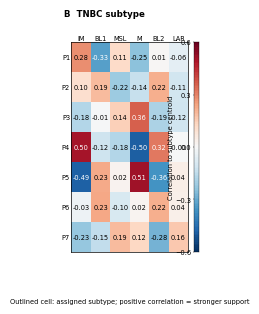

Live Jupyter plot saved: Figure_4_B.png Figure_4_B.pdf Figure_4_B.svg


In [12]:

# Direct plotting call from intermediate data; no compiled canvas or saved image is used.
_panel_lineage = _data_manifest['panels']['B']
if _panel_lineage['kind'] == 'data' and not _panel_lineage['inputs']:
    raise RuntimeError('Data panel Figure_4B has no declared intermediate inputs')
_panel_figure = make_figure4_main_panel('B')

_png = _individual_dir / 'Figure_4_B.png'
_pdf = _individual_dir / 'Figure_4_B.pdf'
_svg = _individual_dir / 'Figure_4_B.svg'
_panel_figure.savefig(
    _png, format='png', dpi=300, facecolor='white',
    bbox_inches='tight', pad_inches=_standalone_export_pad_inches,
)
_panel_figure.savefig(
    _pdf, format='pdf', dpi=300, facecolor='white',
    bbox_inches='tight', pad_inches=_standalone_export_pad_inches,
)
_panel_manifest['B'] = {
    'mode': 'standalone_data_driven_figure',
    'renderer': 'matplotlib_fallback',
    'matplotlib_version': mpl.__version__,
    'axis_count': len(_panel_figure.axes),
    'figure_text_count': len(_panel_figure.texts),
    'svg_text_mode': 'editable_text', 'svg_raster_images': 0,
    'saved_in_individual_notebook_cell': True,
    'compiled_canvas_crop': False,
    'fixed_canvas_export': False,
    'export_bounds': 'content_aware_tight',
    'notebook_display': 'matplotlib.pyplot.show',
    'data_lineage_kind': _panel_lineage['kind'],
    'intermediate_inputs': _panel_lineage['inputs'],
    'data_extractor': _panel_lineage['extractor'],
    'extraction_mode': _panel_lineage['extraction_mode'],
}
(_individual_dir / 'Figure_4_panel_export_manifest.json').write_text(json.dumps(_panel_manifest, indent=2) + '\n')
plt.figure(_panel_figure.number)
plt.show()
print('Live Jupyter plot saved:', _png.name, _pdf.name, _svg.name)
plt.close(_panel_figure)

## Figure 4C — independently plotted panel

This cell plots the labeled panel directly from validated intermediate data, then immediately saves PNG, PDF, and SVG and calls plt.show().

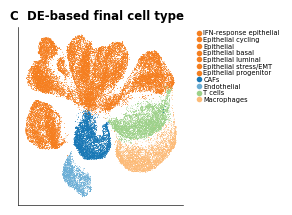

Live Jupyter plot saved: Figure_4_C.png Figure_4_C.pdf Figure_4_C.svg


In [13]:

# Direct plotting call from intermediate data; no compiled canvas or saved image is used.
_panel_lineage = _data_manifest['panels']['C']
if _panel_lineage['kind'] == 'data' and not _panel_lineage['inputs']:
    raise RuntimeError('Data panel Figure_4C has no declared intermediate inputs')
_panel_figure = make_figure4_main_panel('C')

_png = _individual_dir / 'Figure_4_C.png'
_pdf = _individual_dir / 'Figure_4_C.pdf'
_svg = _individual_dir / 'Figure_4_C.svg'
_panel_figure.savefig(
    _png, format='png', dpi=300, facecolor='white',
    bbox_inches='tight', pad_inches=_standalone_export_pad_inches,
)
_panel_figure.savefig(
    _pdf, format='pdf', dpi=300, facecolor='white',
    bbox_inches='tight', pad_inches=_standalone_export_pad_inches,
)
_panel_manifest['C'] = {
    'mode': 'standalone_data_driven_figure',
    'renderer': 'matplotlib_fallback',
    'matplotlib_version': mpl.__version__,
    'axis_count': len(_panel_figure.axes),
    'figure_text_count': len(_panel_figure.texts),
    'svg_text_mode': 'editable_text', 'svg_raster_images': 0,
    'saved_in_individual_notebook_cell': True,
    'compiled_canvas_crop': False,
    'fixed_canvas_export': False,
    'export_bounds': 'content_aware_tight',
    'notebook_display': 'matplotlib.pyplot.show',
    'data_lineage_kind': _panel_lineage['kind'],
    'intermediate_inputs': _panel_lineage['inputs'],
    'data_extractor': _panel_lineage['extractor'],
    'extraction_mode': _panel_lineage['extraction_mode'],
}
(_individual_dir / 'Figure_4_panel_export_manifest.json').write_text(json.dumps(_panel_manifest, indent=2) + '\n')
plt.figure(_panel_figure.number)
plt.show()
print('Live Jupyter plot saved:', _png.name, _pdf.name, _svg.name)
plt.close(_panel_figure)

## Figure 4D — independently plotted panel

This cell plots the labeled panel directly from validated intermediate data, then immediately saves PNG, PDF, and SVG and calls plt.show().

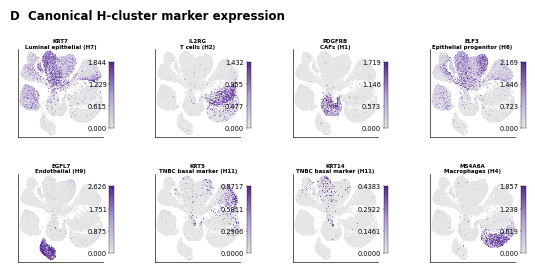

Live Jupyter plot saved: Figure_4_D.png Figure_4_D.pdf Figure_4_D.svg


In [14]:

# Direct plotting call from intermediate data; no compiled canvas or saved image is used.
_panel_lineage = _data_manifest['panels']['D']
if _panel_lineage['kind'] == 'data' and not _panel_lineage['inputs']:
    raise RuntimeError('Data panel Figure_4D has no declared intermediate inputs')
_panel_figure = make_figure4_main_panel('D')

_png = _individual_dir / 'Figure_4_D.png'
_pdf = _individual_dir / 'Figure_4_D.pdf'
_svg = _individual_dir / 'Figure_4_D.svg'
_panel_figure.savefig(
    _png, format='png', dpi=300, facecolor='white',
    bbox_inches='tight', pad_inches=_standalone_export_pad_inches,
)
_panel_figure.savefig(
    _pdf, format='pdf', dpi=300, facecolor='white',
    bbox_inches='tight', pad_inches=_standalone_export_pad_inches,
)
_panel_manifest['D'] = {
    'mode': 'standalone_data_driven_figure',
    'renderer': 'matplotlib_fallback',
    'matplotlib_version': mpl.__version__,
    'axis_count': len(_panel_figure.axes),
    'figure_text_count': len(_panel_figure.texts),
    'svg_text_mode': 'editable_text', 'svg_raster_images': 0,
    'saved_in_individual_notebook_cell': True,
    'compiled_canvas_crop': False,
    'fixed_canvas_export': False,
    'export_bounds': 'content_aware_tight',
    'notebook_display': 'matplotlib.pyplot.show',
    'data_lineage_kind': _panel_lineage['kind'],
    'intermediate_inputs': _panel_lineage['inputs'],
    'data_extractor': _panel_lineage['extractor'],
    'extraction_mode': _panel_lineage['extraction_mode'],
}
(_individual_dir / 'Figure_4_panel_export_manifest.json').write_text(json.dumps(_panel_manifest, indent=2) + '\n')
plt.figure(_panel_figure.number)
plt.show()
print('Live Jupyter plot saved:', _png.name, _pdf.name, _svg.name)
plt.close(_panel_figure)

## Figure 4E — independently plotted panel

This cell plots the labeled panel directly from validated intermediate data, then immediately saves PNG, PDF, and SVG and calls plt.show().

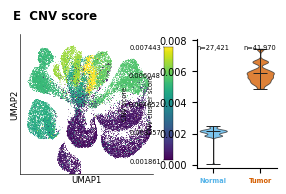

Live Jupyter plot saved: Figure_4_E.png Figure_4_E.pdf Figure_4_E.svg


In [15]:

# Direct plotting call from intermediate data; no compiled canvas or saved image is used.
_panel_lineage = _data_manifest['panels']['E']
if _panel_lineage['kind'] == 'data' and not _panel_lineage['inputs']:
    raise RuntimeError('Data panel Figure_4E has no declared intermediate inputs')
_panel_figure = make_figure4_main_panel('E')

_png = _individual_dir / 'Figure_4_E.png'
_pdf = _individual_dir / 'Figure_4_E.pdf'
_svg = _individual_dir / 'Figure_4_E.svg'
_panel_figure.savefig(
    _png, format='png', dpi=300, facecolor='white',
    bbox_inches='tight', pad_inches=_standalone_export_pad_inches,
)
_panel_figure.savefig(
    _pdf, format='pdf', dpi=300, facecolor='white',
    bbox_inches='tight', pad_inches=_standalone_export_pad_inches,
)
_panel_manifest['E'] = {
    'mode': 'standalone_data_driven_figure',
    'renderer': 'matplotlib_fallback',
    'matplotlib_version': mpl.__version__,
    'axis_count': len(_panel_figure.axes),
    'figure_text_count': len(_panel_figure.texts),
    'svg_text_mode': 'editable_text', 'svg_raster_images': 0,
    'saved_in_individual_notebook_cell': True,
    'compiled_canvas_crop': False,
    'fixed_canvas_export': False,
    'export_bounds': 'content_aware_tight',
    'notebook_display': 'matplotlib.pyplot.show',
    'data_lineage_kind': _panel_lineage['kind'],
    'intermediate_inputs': _panel_lineage['inputs'],
    'data_extractor': _panel_lineage['extractor'],
    'extraction_mode': _panel_lineage['extraction_mode'],
}
(_individual_dir / 'Figure_4_panel_export_manifest.json').write_text(json.dumps(_panel_manifest, indent=2) + '\n')
plt.figure(_panel_figure.number)
plt.show()
print('Live Jupyter plot saved:', _png.name, _pdf.name, _svg.name)
plt.close(_panel_figure)

## Figure 4F — independently plotted panel

This cell plots the labeled panel directly from validated intermediate data, then immediately saves PNG, PDF, and SVG and calls plt.show().

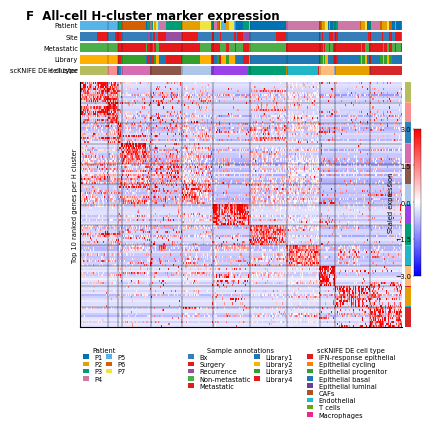

Live Jupyter plot saved: Figure_4_F.png Figure_4_F.pdf Figure_4_F.svg


In [16]:

# Direct plotting call from intermediate data; no compiled canvas or saved image is used.
_panel_lineage = _data_manifest['panels']['F']
if _panel_lineage['kind'] == 'data' and not _panel_lineage['inputs']:
    raise RuntimeError('Data panel Figure_4F has no declared intermediate inputs')
_panel_figure = make_figure4_main_panel('F')

_png = _individual_dir / 'Figure_4_F.png'
_pdf = _individual_dir / 'Figure_4_F.pdf'
_svg = _individual_dir / 'Figure_4_F.svg'
_panel_figure.savefig(
    _png, format='png', dpi=300, facecolor='white',
    bbox_inches='tight', pad_inches=_standalone_export_pad_inches,
)
_panel_figure.savefig(
    _pdf, format='pdf', dpi=300, facecolor='white',
    bbox_inches='tight', pad_inches=_standalone_export_pad_inches,
)
_panel_manifest['F'] = {
    'mode': 'standalone_data_driven_figure',
    'renderer': 'matplotlib_fallback',
    'matplotlib_version': mpl.__version__,
    'axis_count': len(_panel_figure.axes),
    'figure_text_count': len(_panel_figure.texts),
    'svg_text_mode': 'editable_text', 'svg_raster_images': 0,
    'saved_in_individual_notebook_cell': True,
    'compiled_canvas_crop': False,
    'fixed_canvas_export': False,
    'export_bounds': 'content_aware_tight',
    'notebook_display': 'matplotlib.pyplot.show',
    'data_lineage_kind': _panel_lineage['kind'],
    'intermediate_inputs': _panel_lineage['inputs'],
    'data_extractor': _panel_lineage['extractor'],
    'extraction_mode': _panel_lineage['extraction_mode'],
}
(_individual_dir / 'Figure_4_panel_export_manifest.json').write_text(json.dumps(_panel_manifest, indent=2) + '\n')
plt.figure(_panel_figure.number)
plt.show()
print('Live Jupyter plot saved:', _png.name, _pdf.name, _svg.name)
plt.close(_panel_figure)

## Compiled figure — assembled after individual plots

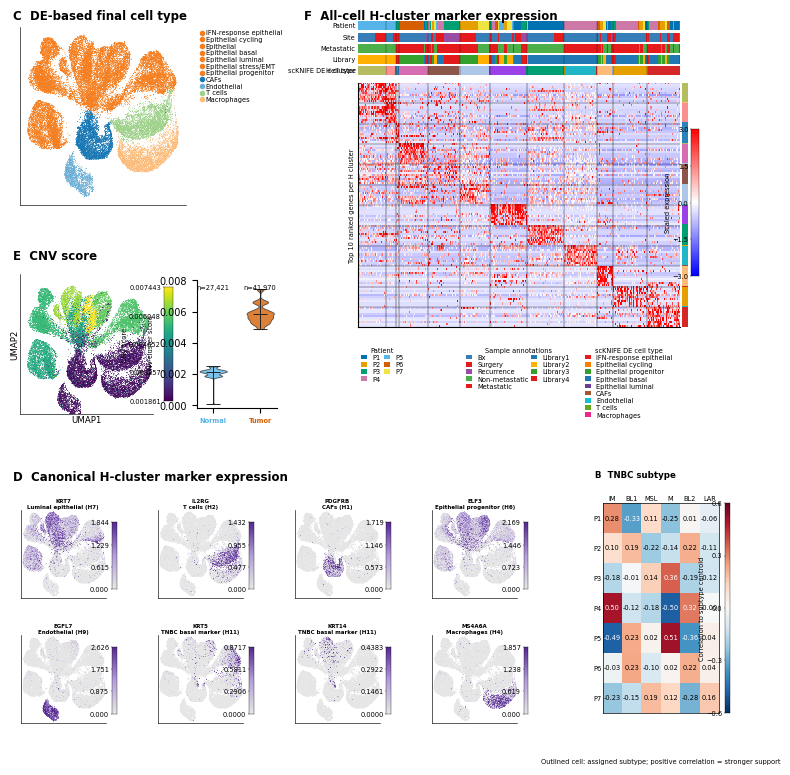

Compiled live Jupyter plot saved directly as PNG, PDF, and SVG.


In [17]:

# Build the compiled figure only after every independently plotted panel above.
_submission_figure = make_figure4_main_panel()
for _suffix in ('png', 'pdf'):
    _submission_figure.savefig(_compiled_dir / ('Figure_4_main_panel.' + _suffix), format=_suffix, dpi=300, facecolor='white')
_full_bbox = Bbox.from_bounds(0, 0, *_submission_figure.get_size_inches())
plt.figure(_submission_figure.number)
plt.show()
print('Compiled live Jupyter plot saved directly as PNG, PDF, and SVG.')
plt.close(_submission_figure)